<a href="https://colab.research.google.com/github/Toira818/final-square-well/blob/main/finite_square_well_github.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy import optimize

import warnings
warnings.filterwarnings('ignore')

# Physical constants for scaling calculations
hbar = 1.05457180013e-34            # J*s
melec = 9.10938356e-31             # kg
eVtoJ = 1.60217662e-19 # conversion factor from eV to Joules
AngstromtoMeter = 1e-10 # conversion factor from Angstroms to meters
val = np.sqrt(2.0*melec*eVtoJ)*AngstromtoMeter/(2.0*hbar) # prefactor sqrt(2*melec)/(2*hbar), for when L is in angstroms and Vo is in eV




In [ ]:
L = 10
Vo = 5

x = np.linspace(-L, L, 1000)


def potential(x, Vo, L):
    Vx = np.zeros(len(x))          #creates an array, Vx, filled with same amount of zeroes as x's (1000)
    for i in range(len(x)):
        if x[i]<=-L/2 or x[i]>=L/2:
            Vx[i] = Vo             #if x[i]<=-L/2 or x[i]>=L/2, then Vx is no longer zero and becomes Vo

    return Vx

Vx = potential(x, Vo, L)





def f_even(E,Vo,L):
    return(np.sqrt(Vo-E)-np.sqrt(E)*np.tan(L*np.sqrt(E)*val))
def f_odd(E,Vo,L):
    return(np.sqrt(Vo-E)+np.sqrt(E)/np.tan(L*np.sqrt(E)*val))

def find_state_energies(Vo,L,step=0.01):

    sol = np.array([],dtype=float) #empty array to store all solutions function finds
    E = np.arange(step,Vo,step) #array of energies starting from step going up to, but not including, Vo with each value separated by step.
    even=True

    for i in range(len(E)-1):  # loop needs to access E[i] and E[i+1]
        if even==True:
            if f_even(E[i], Vo, L)*f_even(E[i+1], Vo, L)<0: #sees if function changed sign between points (crossed x-axis and value was zero)
                sol=np.append(sol,optimize.brentq(f_even,E[i],E[i+1],args=(Vo, L)) ) #brentq finds E value where f_even is zero and np.append stores energy in sol
                even=False   #makes even=false so odd solutions can be found next
        if even==False:
            if f_odd(E[i], Vo, L)*f_odd(E[i+1], Vo, L)<0:
                sol=np.append(sol,optimize.brentq(f_odd,E[i],E[i+1],args=(Vo, L)))
                even=True

    #return the energies of the states and the number of states
    return sol, len(sol)





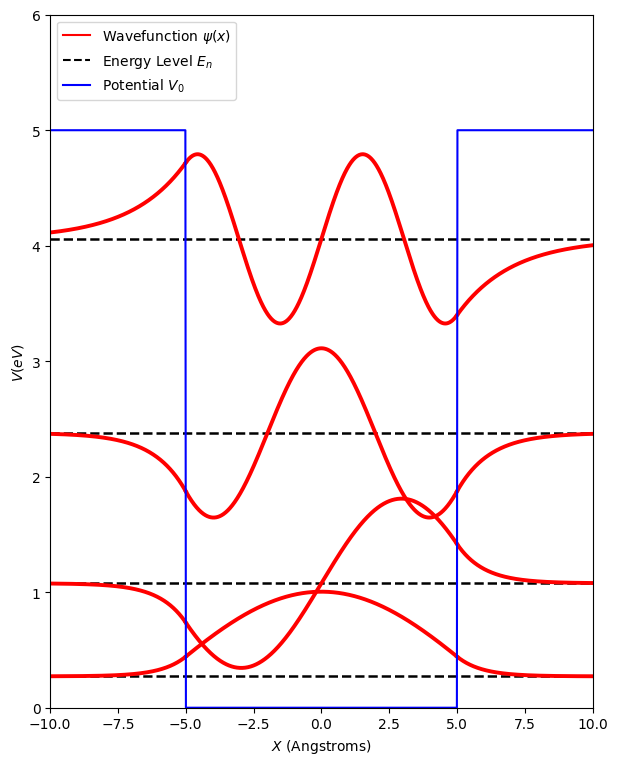

In [ ]:
#find the energies of the states for the given Vo and L
E_vals, nstates = find_state_energies(Vo, L)


fig, ax = plt.subplots(1, 1, figsize=(7, 9))

#create x values for each of region I, II & III
X_lef = np.linspace(-L, -L/2.0, 900, endpoint=True)  #endpoint=True includes the end value in the array
X_mid = np.linspace(-L/2.0, L/2.0, 900, endpoint=True)
X_rig = np.linspace(L/2.0, L, 900, endpoint=True)


ax.axis([-L, L, 0.0, 1.2*Vo])    # x-axis from -L to L, y-axis from 0 to 120% of Vo
ax.set_xlabel(r'$X$ (Angstroms)')
ax.set_ylabel(r'$V (eV)$')

# Define the maximum amplitude of the wavefunction
if (nstates > 1):
    amp = np.sqrt((E_vals[1]-E_vals[0])/1.5)   #amp is difference between the energy levels and 1.5 as an arbitrary scaling factor
else:
    amp = np.sqrt((Vo-E_vals[0])/1.5)

# Plot the wavefunctions
for n in range(1, nstates+1):

    ax.hlines(E_vals[n-1], -L, L, linewidth=1.8, linestyle='--', color="black")    #draws a line to indicate the energy levels
    k = 2.0*np.sqrt(E_vals[n-1])*val
    a0 = 2.0*np.sqrt(Vo-E_vals[n-1])*val
    # Ploting odd wavefunction
    if (n%2==0):      #if n is even
        ax.plot(X_lef, E_vals[n-1]-amp*np.exp(a0*L/2.0)*np.sin(k*L/2.0)*np.exp(a0*X_lef), color="red", label="", linewidth=2.8)     #added to or subtracted from E_vals[n-1] so that the wavefunction is in line with its energy value
        ax.plot(X_mid, E_vals[n-1]+amp*np.sin(k*X_mid), color="red", label="", linewidth=2.8)
        ax.plot(X_rig, E_vals[n-1]+amp*np.exp(a0*L/2.0)*np.sin(k*L/2.0)*np.exp(-a0*X_rig), color="red", label="", linewidth=2.8)
    # Plot even wavefunction
    else:
        ax.plot(X_lef, E_vals[n-1]+amp*np.exp(a0*L/2.0)*np.cos(k*L/2.0)*np.exp(a0*X_lef), color="red", label="", linewidth=2.8)
        ax.plot(X_mid, E_vals[n-1]+amp*np.cos(k*X_mid), color="red", label="", linewidth=2.8)
        ax.plot(X_rig, E_vals[n-1]+amp*np.exp(a0*L/2.0)*np.cos(k*L/2.0)*np.exp(-a0*X_rig), color="red", label="", linewidth=2.8)


ax.plot(x, Vx, color='blue', linewidth=1.5)

#create a legend

handles, labels = ax.get_legend_handles_labels()
line = Line2D([0], [0], label='Wavefunction $\psi(x)$', color='red', linestyle='-')
handles.append(line)
line = Line2D([0], [0], label='Energy Level $E_n$', color='black', linestyle='--')
handles.append(line)
line = Line2D([0], [0], label='Potential $V_0$', color='blue', linestyle='-')
handles.append(line)

ax.legend(handles=handles, loc=2)

plt.show()
